# 1. Importing libraries and dataset and dictionary

In [1]:
from sklearn.decomposition import PCA 
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay, accuracy_score
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn import metrics      
import sklearn.preprocessing as preproc

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme()

In [2]:
# Importing Dataset
df = pd.read_csv("Salary_Data_Based_country_and_race.csv", index_col="Unnamed: 0")
# Renaming columns
df.columns = df.columns.str.replace(" ","_").str.lower()
# Printing first 5 rows
df.head()

,age,gender,education_level,job_title,years_of_experience,salary,country,race
0,32.0,Male,Bachelor's,Software Engineer,5.0,90000.0,UK,White
1,28.0,Female,Master's,Data Analyst,3.0,65000.0,USA,Hispanic
2,45.0,Male,PhD,Senior Manager,15.0,150000.0,Canada,White
3,36.0,Female,Bachelor's,Sales Associate,7.0,60000.0,USA,Hispanic
4,52.0,Male,Master's,Director,20.0,200000.0,USA,Asian


In [3]:
# Inspecting Dataset
print(f"The dataframe contains {df.isnull().sum().sum()} null values.")
print("=============== Total number of null values in each feature  ===============")
df_null = df.isnull().sum()
df_null = df_null[df_null>0]
df_null


The dataframe contains 17 null values.
=============== Total number of null values in each feature  ===============


age                    2
gender                 2
education_level        3
job_title              2
years_of_experience    3
salary                 5
dtype: int64

In [4]:
# Dropping null values
df = df.dropna()

# Reseting index
df.reset_index(drop =True)

,age,gender,education_level,job_title,years_of_experience,salary,country,race
0,32.0,Male,Bachelor's,Software Engineer,5.0,90000.0,UK,White
1,28.0,Female,Master's,Data Analyst,3.0,65000.0,USA,Hispanic
2,45.0,Male,PhD,Senior Manager,15.0,150000.0,Canada,White
3,36.0,Female,Bachelor's,Sales Associate,7.0,60000.0,USA,Hispanic
4,52.0,Male,Master's,Director,20.0,200000.0,USA,Asian
...,...,...,...,...,...,...,...,...
6693,49.0,Female,PhD,Director of Marketing,20.0,200000.0,UK,Mixed
6694,32.0,Male,High School,Sales Associate,3.0,50000.0,Australia,Australian
6695,30.0,Female,Bachelor's Degree,Financial Manager,4.0,55000.0,China,Chinese
6696,46.0,Male,Master's Degree,Marketing Manager,14.0,140000.0,China,Korean


In [5]:
# Dataframe shape
print(f"The dataframe contains {df.shape[0]} rows / recods, and {df.shape[1]} features / variables.")

The dataframe contains 6698 rows / recods, and 8 features / variables.


# Data Cleaning

In [6]:
np.where(df["education_level"]=="Master's","Master's Degree",df["education_level"])

array(["Bachelor's", "Master's Degree", 'PhD', ..., "Bachelor's Degree",
       "Master's Degree", 'High School'], shape=(6698,), dtype=object)

In [7]:
df["education_level"].str.replace({"Master's Degree":"Master's Degree"}).value_counts()

education_level
Bachelor's Degree    2265
Master's Degree      1572
PhD                  1368
Bachelor's            756
High School           448
Master's              288
phD                     1
Name: count, dtype: int64

In [8]:
df["education_level"] = df["education_level"].str.replace({"Master's":"Master's Degree",
                                   "Bachelor's":"Bachelor's Degree",
                                   "phD":"PhD"})

In [9]:
df["education_level"].value_counts()

education_level
Bachelor's Degree Degree    2265
Master's Degree Degree      1572
PhD                         1369
Bachelor's Degree            756
High School                  448
Master's Degree              288
Name: count, dtype: int64

In [10]:
df["education_level"].unique()

<ArrowStringArray>
[       'Bachelor's Degree',          'Master's Degree',
                      'PhD', 'Bachelor's Degree Degree',
   'Master's Degree Degree',              'High School']
Length: 6, dtype: str

# EDA visualizations

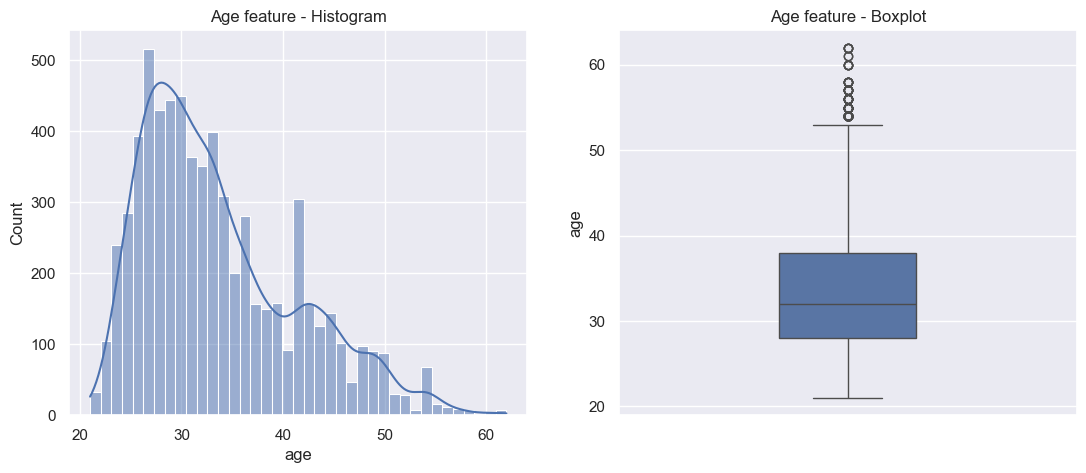

,count,mean,std,min,25%,50%,75%,max
age,6698.0,33.623022,7.615784,21.0,28.0,32.0,38.0,62.0


In [40]:
plt.figure(figsize=(13,5))
plt.subplot(1,2,1)
sns.histplot(df["age"], kde=True)
plt.title("Age feature - Histogram")
plt.subplot(1,2,2)
sns.boxplot(y=df["age"], width=0.3)
plt.title("Age feature - Boxplot")
plt.show()

df[["age"]].describe().T

**Findings:**

---

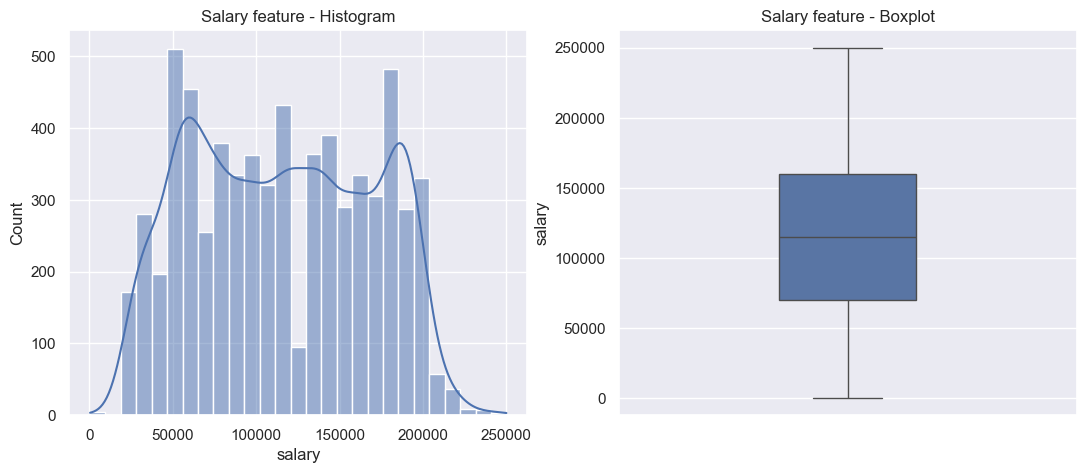

,count,mean,std,min,25%,50%,75%,max
age,6698.0,33.623022,7.615784,21.0,28.0,32.0,38.0,62.0


In [46]:
plt.figure(figsize=(13,5))
plt.subplot(1,2,1)
sns.histplot(df["salary"], kde=True)
plt.title("Salary feature - Histogram")
plt.subplot(1,2,2)
sns.boxplot(y=df["salary"], width=0.3)
plt.title("Salary feature - Boxplot")
plt.show()

df[["age"]].describe().T

**Findings:**

---

<Axes: xlabel='education_level', ylabel='salary'>

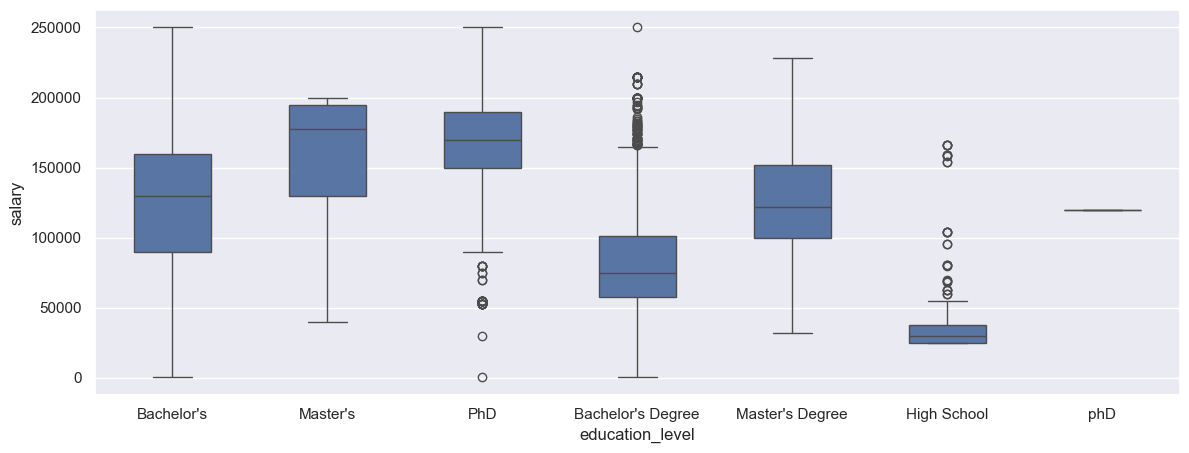

In [53]:
plt.figure(figsize=(14,5))
sns.boxplot(data=df, y="salary", x="education_level", width=0.5)